In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from pathlib import Path
import os

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "task1_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_files = [
    p for p in PROJECT_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_extensions
    and OUTPUT_DIR not in p.parents
]

print("Project folder:", PROJECT_DIR)
print("Images found:")

for i, path in enumerate(image_files):
    print(i, "-", path.relative_to(PROJECT_DIR))


Project folder: C:\Users\lenovo\Desktop\CV_Assignment.ipynb
Images found:
0 - images\image1.jpeg
1 - images\image2.jpeg
2 - task2_outputs\hog_visualization.png
3 - task2_outputs\input_image1.png
4 - task2_outputs\input_image2.png
5 - task2_outputs\sift_feature_matching.png
6 - task2_outputs\sift_keypoints_image1.png
7 - task2_outputs\sift_keypoints_image2.png
8 - task2_outputs\sift_matching_resized.png
9 - task2_outputs\sift_matching_rotated.png
10 - task3_outputs\original_image.png
11 - task3_outputs\viola_jones_result.jpg
12 - task3_outputs\yolo_result.jpg
13 - task3_outputs\frames\frame_1.jpg
14 - task3_outputs\frames\frame_2.jpg
15 - task3_outputs\frames\frame_3.jpg
16 - task3_outputs\frames\frame_4.jpg
17 - task3_outputs\frames\frame_5.jpg
18 - images\.ipynb_checkpoints\image1.jpeg-checkpoint.jpeg


Images available:
0 - images\image1.jpeg
1 - images\image2.jpeg
2 - task2_outputs\hog_visualization.png
3 - task2_outputs\input_image1.png
4 - task2_outputs\input_image2.png
5 - task2_outputs\sift_feature_matching.png
6 - task2_outputs\sift_keypoints_image1.png
7 - task2_outputs\sift_keypoints_image2.png
8 - task2_outputs\sift_matching_resized.png
9 - task2_outputs\sift_matching_rotated.png
10 - task3_outputs\frames\frame_1.jpg
11 - task3_outputs\frames\frame_2.jpg
12 - task3_outputs\frames\frame_3.jpg
13 - task3_outputs\frames\frame_4.jpg
14 - task3_outputs\frames\frame_5.jpg
15 - task3_outputs\original_image.png
16 - task3_outputs\viola_jones_result.jpg
17 - task3_outputs\yolo_result.jpg
Selected image: image1.jpeg
Image dimensions: (400, 600, 3)


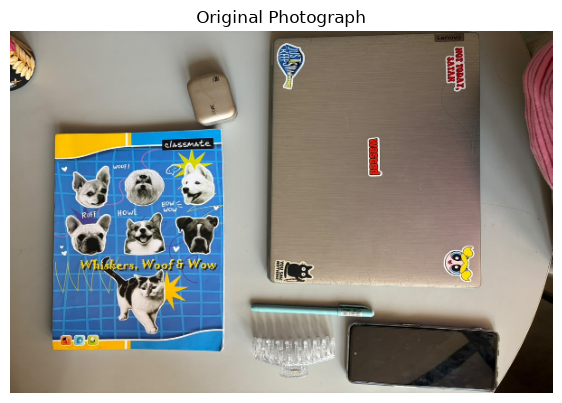

True

In [22]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "task1_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

image_files = sorted([
    p for p in PROJECT_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in image_extensions
    and OUTPUT_DIR not in p.parents
    and ".ipynb_checkpoints" not in p.parts
])

print("Images available:")
for i, path in enumerate(image_files):
    print(i, "-", path.relative_to(PROJECT_DIR))

image_index = 0

if not image_files:
    raise FileNotFoundError("No images found. Place your photograph inside the images folder.")

IMAGE_PATH = image_files[image_index]
original_bgr = cv2.imread(str(IMAGE_PATH))

if original_bgr is None:
    raise ValueError("The selected image could not be opened.")

original = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)
original = cv2.resize(original, (600, 400))

gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

print("Selected image:", IMAGE_PATH.name)
print("Image dimensions:", original.shape)

plt.figure(figsize=(7, 5))
plt.imshow(original)
plt.title("Original Photograph")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "original_image.png"),
    cv2.cvtColor(original, cv2.COLOR_RGB2BGR)
)

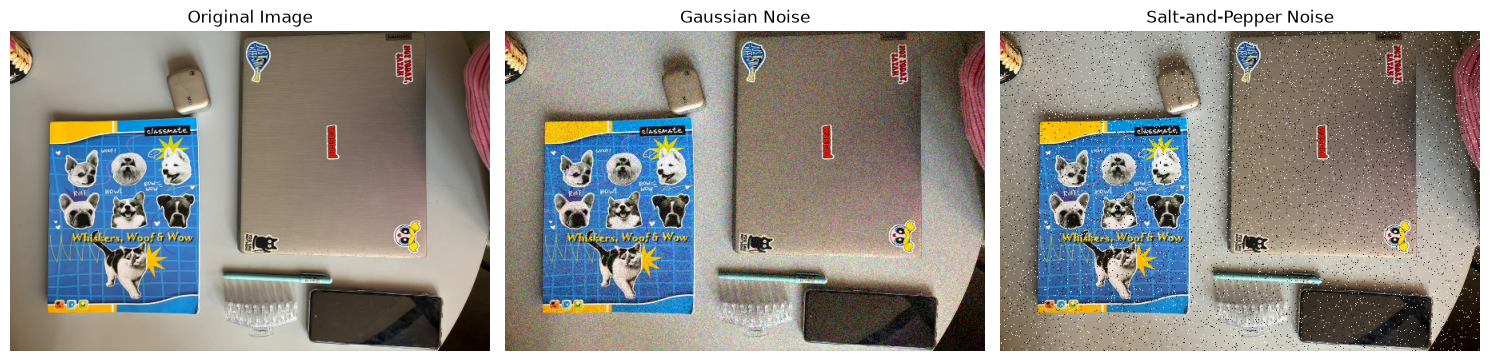

True

In [23]:
np.random.seed(42)

original_float = original.astype(np.float32) / 255.0

gaussian_noise = np.random.normal(
    0, 0.08, original_float.shape
)

gaussian_noisy = np.clip(
    original_float + gaussian_noise, 0, 1
)

gaussian_noisy = (gaussian_noisy * 255).astype(np.uint8)

salt_pepper_noisy = original.copy()
noise_amount = 0.04
total_pixels = original.shape[0] * original.shape[1]
number_of_noise_pixels = int(noise_amount * total_pixels)

rows = np.random.randint(0, original.shape[0], number_of_noise_pixels)
cols = np.random.randint(0, original.shape[1], number_of_noise_pixels)

salt_pepper_noisy[rows, cols] = np.random.choice(
    [0, 255], size=(number_of_noise_pixels, 1)
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_noisy)
plt.title("Gaussian Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(salt_pepper_noisy)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "gaussian_noisy.png"),
    cv2.cvtColor(gaussian_noisy, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "salt_pepper_noisy.png"),
    cv2.cvtColor(salt_pepper_noisy, cv2.COLOR_RGB2BGR)
)

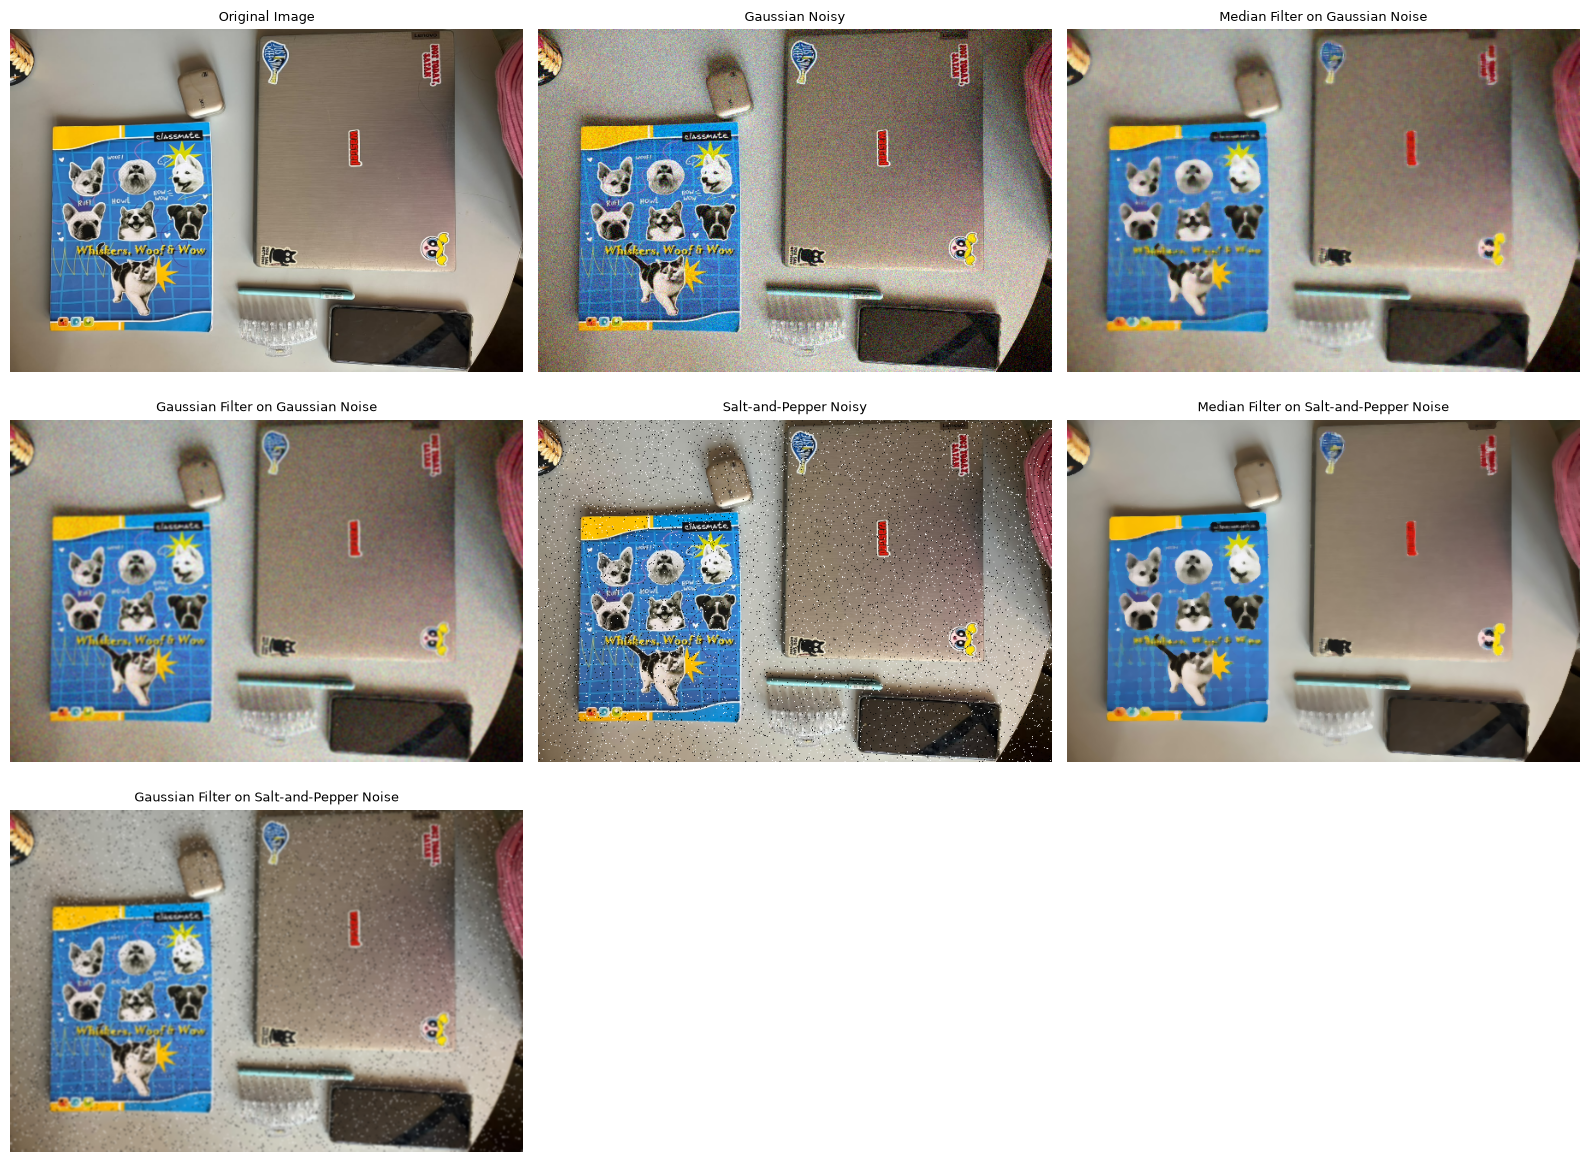

In [24]:
gaussian_median = cv2.medianBlur(gaussian_noisy, 5)
gaussian_filtered = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)

salt_pepper_median = cv2.medianBlur(salt_pepper_noisy, 5)
salt_pepper_gaussian = cv2.GaussianBlur(salt_pepper_noisy, (5, 5), 0)

images_to_display = [
    (original, "Original Image"),
    (gaussian_noisy, "Gaussian Noisy"),
    (gaussian_median, "Median Filter on Gaussian Noise"),
    (gaussian_filtered, "Gaussian Filter on Gaussian Noise"),
    (salt_pepper_noisy, "Salt-and-Pepper Noisy"),
    (salt_pepper_median, "Median Filter on Salt-and-Pepper Noise"),
    (salt_pepper_gaussian, "Gaussian Filter on Salt-and-Pepper Noise")
]

plt.figure(figsize=(16, 12))

for i, (img, title) in enumerate(images_to_display, 1):
    plt.subplot(3, 3, i)
    plt.imshow(img)
    plt.title(title, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

restored_images = {
    "gaussian_median.png": gaussian_median,
    "gaussian_filtered.png": gaussian_filtered,
    "salt_pepper_median.png": salt_pepper_median,
    "salt_pepper_gaussian.png": salt_pepper_gaussian
}

for filename, img in restored_images.items():
    cv2.imwrite(
        str(OUTPUT_DIR / filename),
        cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    )

In [25]:
images_for_metrics = {
    "Gaussian Noise": gaussian_noisy,
    "Gaussian Noise + Median Filter": gaussian_median,
    "Gaussian Noise + Gaussian Filter": gaussian_filtered,
    "Salt-and-Pepper Noise": salt_pepper_noisy,
    "Salt-and-Pepper + Median Filter": salt_pepper_median,
    "Salt-and-Pepper + Gaussian Filter": salt_pepper_gaussian
}

metrics_results = []

for name, img in images_for_metrics.items():
    psnr_value = peak_signal_noise_ratio(
        original, img, data_range=255
    )

    ssim_value = structural_similarity(
        original, img, channel_axis=2, data_range=255
    )

    metrics_results.append({
        "Image": name,
        "PSNR (dB)": round(psnr_value, 2),
        "SSIM": round(ssim_value, 4)
    })

metrics_df = pd.DataFrame(metrics_results)

display(metrics_df)

metrics_df.to_csv(
    OUTPUT_DIR / "restoration_metrics.csv",
    index=False
)

best_psnr = metrics_df.loc[metrics_df["PSNR (dB)"].idxmax()]
best_ssim = metrics_df.loc[metrics_df["SSIM"].idxmax()]

print("Best PSNR result:", best_psnr["Image"])
print("Best SSIM result:", best_ssim["Image"])

,Image,PSNR (dB),SSIM
0,Gaussian Noise,22.05,0.3596
1,Gaussian Noise + Median Filter,24.04,0.7111
2,Gaussian Noise + Gaussian Filter,25.69,0.7321
3,Salt-and-Pepper Noise,19.35,0.4078
4,Salt-and-Pepper + Median Filter,24.48,0.8586
5,Salt-and-Pepper + Gaussian Filter,24.92,0.6751


Best PSNR result: Gaussian Noise + Gaussian Filter
Best SSIM result: Salt-and-Pepper + Median Filter


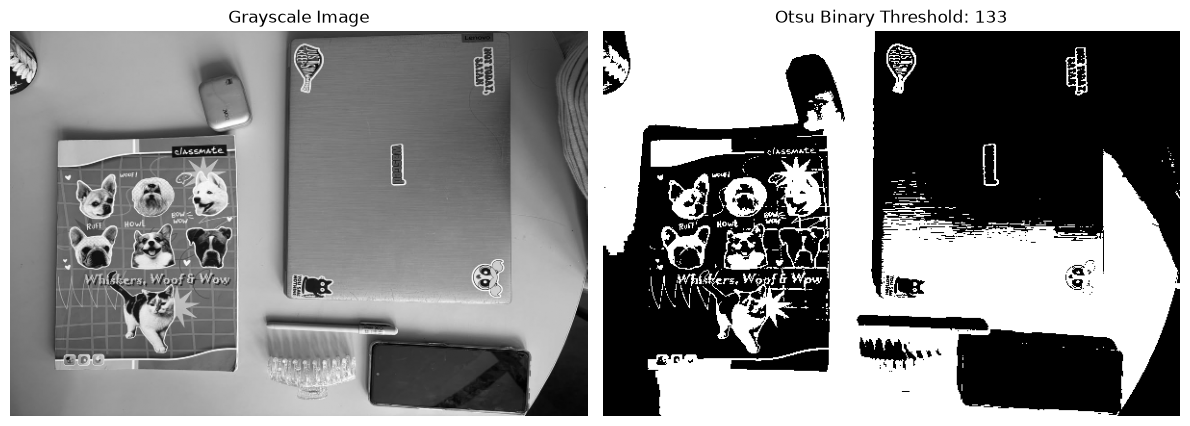

True

In [26]:
gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

threshold_value, binary_image = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray")
plt.title(f"Otsu Binary Threshold: {threshold_value:.0f}")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "grayscale_image.png"), gray
)

cv2.imwrite(
    str(OUTPUT_DIR / "binary_threshold.png"), binary_image
)

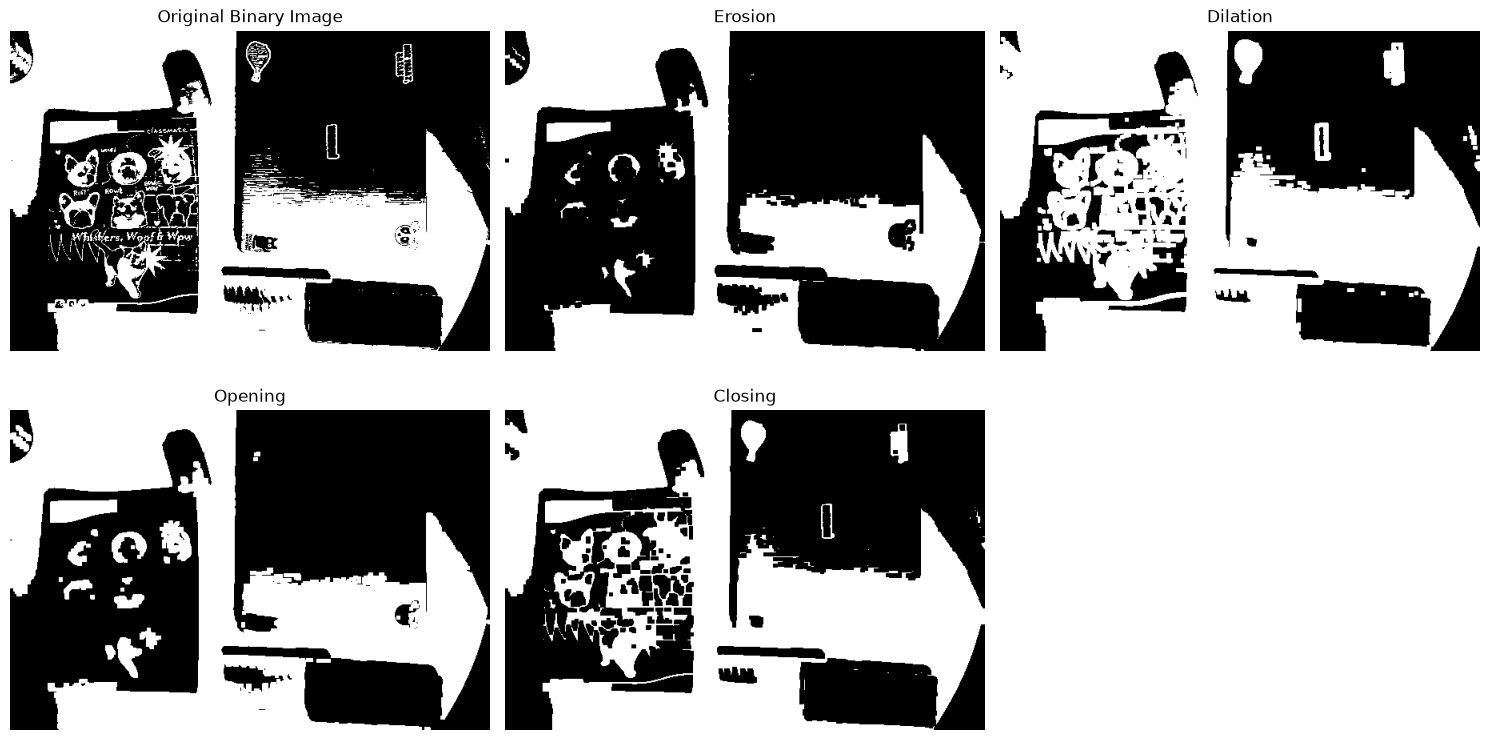

In [27]:
kernel = np.ones((5, 5), np.uint8)

erosion = cv2.erode(binary_image, kernel, iterations=1)
dilation = cv2.dilate(binary_image, kernel, iterations=1)
opening = cv2.morphologyEx(binary_image, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary_image, cv2.MORPH_CLOSE, kernel)

morphological_results = [
    (binary_image, "Original Binary Image"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

plt.figure(figsize=(15, 8))

for i, (img, title) in enumerate(morphological_results, 1):
    plt.subplot(2, 3, i)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

morphological_files = {
    "erosion.png": erosion,
    "dilation.png": dilation,
    "opening.png": opening,
    "closing.png": closing
}

for filename, img in morphological_files.items():
    cv2.imwrite(str(OUTPUT_DIR / filename), img)

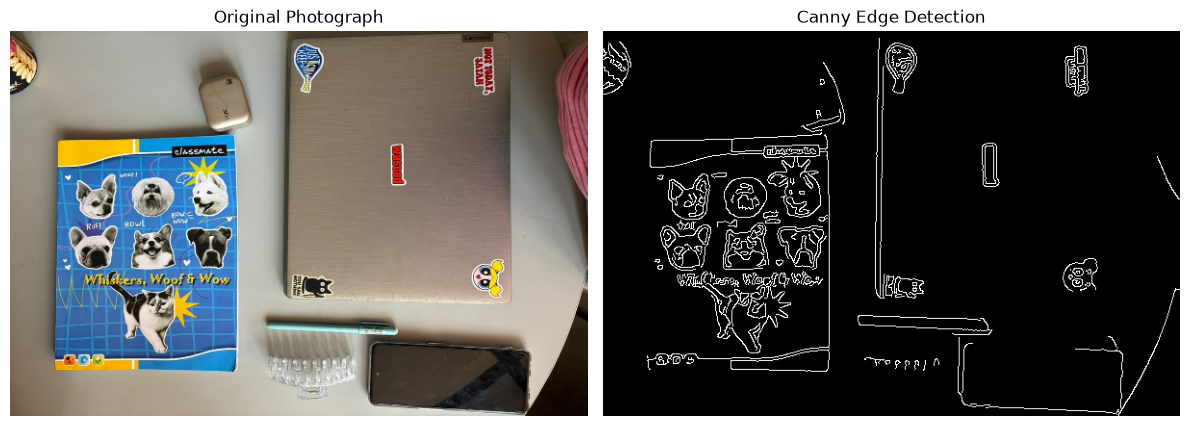

True

In [28]:
blurred_gray = cv2.GaussianBlur(gray, (5, 5), 0)

edges = cv2.Canny(
    blurred_gray,
    threshold1=100,
    threshold2=200
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "canny_edges.png"), edges
)

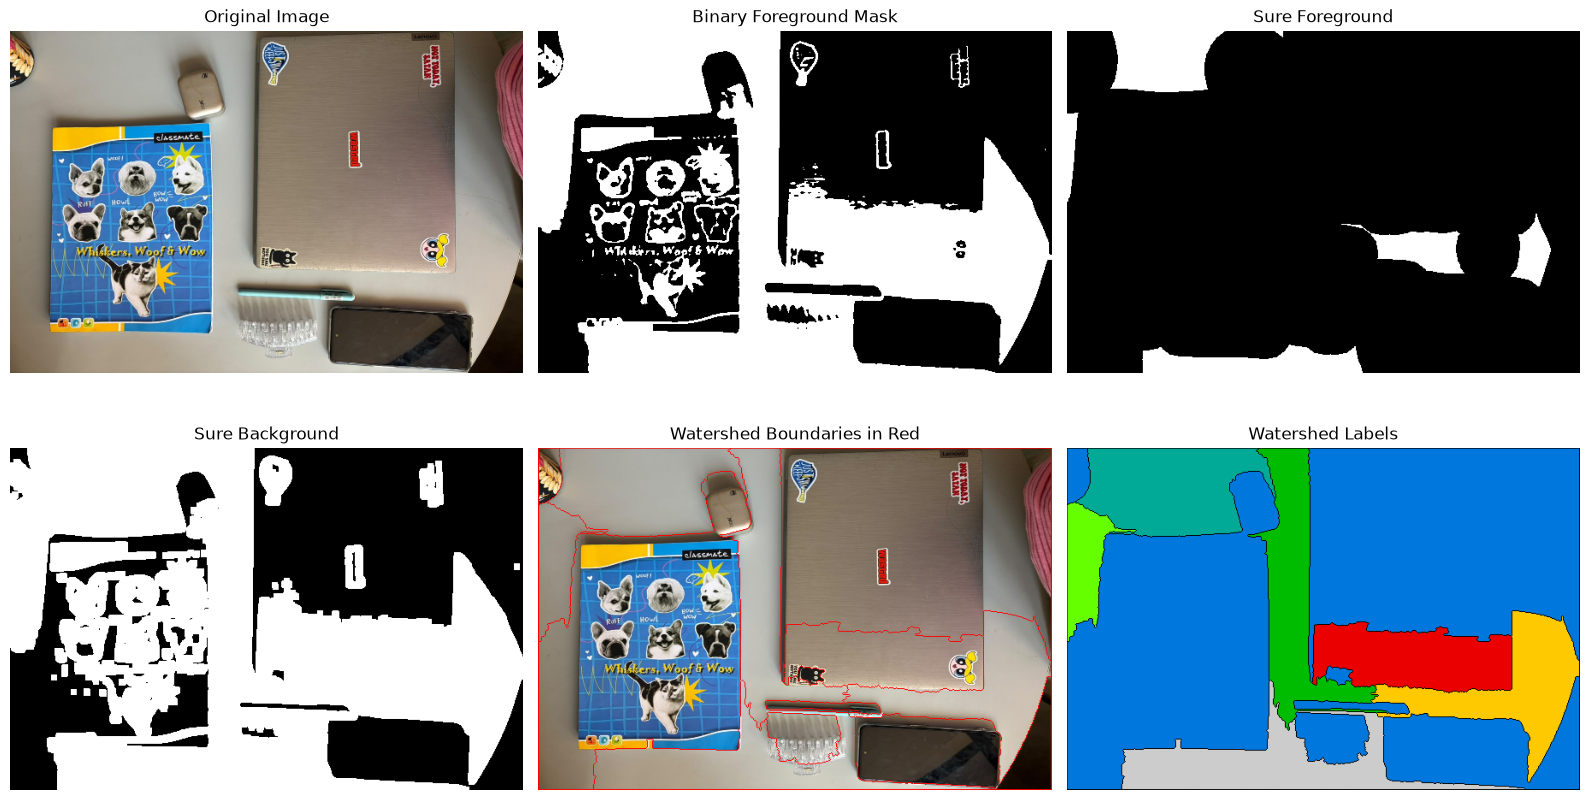

Watershed image used: image1.jpeg
Connected foreground labels detected: 6


In [29]:
watershed_image_index = 0

if len(image_files) > watershed_image_index:
    watershed_path = image_files[watershed_image_index]
else:
    raise FileNotFoundError("A suitable image for watershed was not found.")

watershed_bgr = cv2.imread(str(watershed_path))

if watershed_bgr is None:
    raise ValueError("The watershed image could not be opened.")

watershed_bgr = cv2.resize(watershed_bgr, (600, 400))
watershed_rgb = cv2.cvtColor(watershed_bgr, cv2.COLOR_BGR2RGB)
watershed_gray = cv2.cvtColor(watershed_bgr, cv2.COLOR_BGR2GRAY)

watershed_blur = cv2.GaussianBlur(
    watershed_gray, (5, 5), 0
)

_, mask_a = cv2.threshold(
    watershed_blur, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

mask_b = cv2.bitwise_not(mask_a)

fraction_a = np.count_nonzero(mask_a) / mask_a.size
fraction_b = np.count_nonzero(mask_b) / mask_b.size

if fraction_a <= fraction_b:
    binary_mask = mask_a
else:
    binary_mask = mask_b

kernel = np.ones((3, 3), np.uint8)

sure_background = cv2.dilate(
    binary_mask, kernel, iterations=3
)

distance = cv2.distanceTransform(
    binary_mask, cv2.DIST_L2, 5
)

if distance.max() > 0:
    _, sure_foreground = cv2.threshold(
        distance,
        0.35 * distance.max(),
        255,
        cv2.THRESH_BINARY
    )
else:
    sure_foreground = np.zeros_like(binary_mask)

sure_foreground = sure_foreground.astype(np.uint8)

unknown = cv2.subtract(
    sure_background, sure_foreground
)

number_of_labels, markers = cv2.connectedComponents(
    sure_foreground
)

markers = markers + 1
markers[unknown == 255] = 0

markers = cv2.watershed(watershed_bgr, markers)

segmented = watershed_rgb.copy()
segmented[markers == -1] = [255, 0, 0]

plt.figure(figsize=(16, 9))

plt.subplot(2, 3, 1)
plt.imshow(watershed_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Foreground Mask")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sure_foreground, cmap="gray")
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(sure_background, cmap="gray")
plt.title("Sure Background")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(segmented)
plt.title("Watershed Boundaries in Red")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(markers, cmap="nipy_spectral")
plt.title("Watershed Labels")
plt.axis("off")

plt.tight_layout()
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "watershed_binary_mask.png"),
    binary_mask
)

cv2.imwrite(
    str(OUTPUT_DIR / "watershed_sure_foreground.png"),
    sure_foreground
)

cv2.imwrite(
    str(OUTPUT_DIR / "watershed_sure_background.png"),
    sure_background
)

cv2.imwrite(
    str(OUTPUT_DIR / "watershed_segmented.png"),
    cv2.cvtColor(segmented, cv2.COLOR_RGB2BGR)
)

plt.imsave(
    str(OUTPUT_DIR / "watershed_labels.png"),
    markers,
    cmap="nipy_spectral"
)

print("Watershed image used:", watershed_path.name)
print("Connected foreground labels detected:", number_of_labels - 1)


### Watershed Segmentation Observation

The watershed algorithm was applied to segment the image into different regions. The red boundaries show the detected region boundaries, while the watershed label image displays the segmented regions in different colours. The result separates several regions, but some large and irregular regions remain, indicating that segmentation depends on foreground and background markers.


In [30]:
print("TASK 1: IMAGE RESTORATION AND SEGMENTATION")
print("=" * 50)

print("\nRestoration comparison:")
display(metrics_df)

print("\nSaved output files:")

saved_files = sorted(
    p for p in OUTPUT_DIR.iterdir()
    if p.is_file()
)

for file in saved_files:
    print("-", file.name)

print("\nTotal output files:", len(saved_files))
print("Output folder:", OUTPUT_DIR.resolve())

TASK 1: IMAGE RESTORATION AND SEGMENTATION

Restoration comparison:


,Image,PSNR (dB),SSIM
0,Gaussian Noise,22.05,0.3596
1,Gaussian Noise + Median Filter,24.04,0.7111
2,Gaussian Noise + Gaussian Filter,25.69,0.7321
3,Salt-and-Pepper Noise,19.35,0.4078
4,Salt-and-Pepper + Median Filter,24.48,0.8586
5,Salt-and-Pepper + Gaussian Filter,24.92,0.6751



Saved output files:
- binary_threshold.png
- canny_edges.png
- closing.png
- dilation.png
- erosion.png
- gaussian_filtered.png
- gaussian_median.png
- gaussian_noisy.png
- grayscale_image.png
- opening.png
- original_image.png
- restoration_metrics.csv
- salt_pepper_gaussian.png
- salt_pepper_median.png
- salt_pepper_noisy.png
- watershed_binary_mask.png
- watershed_labels.png
- watershed_segmented.png
- watershed_sure_background.png
- watershed_sure_foreground.png

Total output files: 20
Output folder: C:\Users\lenovo\Desktop\CV_Assignment.ipynb\task1_outputs


## Conclusion

In this task, image restoration and segmentation techniques were applied to the selected image. Gaussian filtering was effective in reducing Gaussian noise, while median filtering performed better for removing salt-and-pepper noise. PSNR and SSIM were used to evaluate the restored images. Thresholding and morphological operations helped process binary images, while Canny edge detection identified image boundaries. Watershed segmentation divided the image into different regions, although some regions remained irregular. Overall, the results demonstrate that the effectiveness of each technique depends on the type of noise and the characteristics of the image.